# k-NN From Scratch - Distances, KD-Tree Search, Tie Handling

In [1]:
import time, heapq
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)
centers = np.array([[0, 0], [2.5, 2.5], [0, 4]])
n_per = 7000
X = np.vstack([rng.normal(c, 1.3, (n_per, 2)) for c in centers])
y = np.repeat([0, 1, 2], n_per)

idx = rng.permutation(len(X)); s = int(0.9 * len(X))
X_train, y_train, X_test, y_test = X[idx[:s]], y[idx[:s]], X[idx[s:]], y[idx[s:]]

mu, sd = X_train.mean(0), X_train.std(0)           
X_train, X_test = (X_train - mu) / sd, (X_test - mu) / sd
print(X_train.shape, X_test.shape)

(18900, 2) (2100, 2)


In [3]:
def euclidean(A, B):
    sq = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T
    return np.sqrt(np.maximum(sq, 0))

def manhattan(A, B):
    return np.abs(A[:, None, :] - B[None, :, :]).sum(2)

# check: vectorized vs simple loop
a, b = X_test[:3], X_train[:4]
loop = np.array([[np.sqrt(np.sum((p - q) ** 2)) for q in b] for p in a])
print('Max difference vs loop:', np.abs(euclidean(a, b) - loop).max())

Max difference vs loop: 2.220446049250313e-16


In [4]:
def vote(labels, dists, n_classes=3, tie_break=True):
    counts = np.bincount(labels, minlength=n_classes)
    tied = np.flatnonzero(counts == counts.max())         
    if len(tied) == 1 or not tie_break:
        return tied[0], len(tied) > 1                    
    total = [dists[labels == c].sum() for c in tied]      
    return tied[int(np.argmin(total))], True              

In [5]:
class BruteKNN:
    def __init__(self, k=5, chunk=500, tie_break=True):
        self.k, self.chunk, self.tie_break = k, chunk, tie_break

    def fit(self, X, y):
        self.X, self.y = X, y
        return self

    def kneighbors(self, Q):
        idx_all, dist_all = [], []
        for i in range(0, len(Q), self.chunk):              
            D = euclidean(Q[i:i + self.chunk], self.X)
            nn = np.argpartition(D, self.k, axis=1)[:, :self.k]  
            d = np.take_along_axis(D, nn, 1)
            o = np.argsort(d, 1)                             
            idx_all.append(np.take_along_axis(nn, o, 1)); dist_all.append(np.take_along_axis(d, o, 1))
        return np.vstack(dist_all), np.vstack(idx_all)

    def predict(self, Q):
        dist, idx = self.kneighbors(Q)
        out = [vote(self.y[i], d, tie_break=self.tie_break) for i, d in zip(idx, dist)]
        self.n_ties = sum(t for _, t in out)
        return np.array([p for p, _ in out])

In [6]:
class KDTree:
    def __init__(self, X, leaf_size=40):
        self.X, self.leaf = X, leaf_size
        self.root = self._build(np.arange(len(X)))

    def _build(self, ids):
        if len(ids) <= self.leaf:
            return ('leaf', ids)
        P = self.X[ids]
        dim = int(np.argmax(P.max(0) - P.min(0)))
        order = ids[np.argsort(P[:, dim])]
        mid = len(order) // 2
        return ('node', dim, self.X[order[mid], dim], self._build(order[:mid]), self._build(order[mid:]))

    def query(self, q, k):
        heap = []                                             
        def search(node):
            if node[0] == 'leaf':
                d = np.sqrt(((self.X[node[1]] - q) ** 2).sum(1))
                for dist, i in zip(d, node[1]):
                    if len(heap) < k: heapq.heappush(heap, (-dist, i))
                    elif dist < -heap[0][0]: heapq.heapreplace(heap, (-dist, i))
                return
            _, dim, split, left, right = node
            near, far = (left, right) if q[dim] < split else (right, left)
            search(near)
            if len(heap) < k or abs(q[dim] - split) < -heap[0][0]:   
                search(far)
        search(self.root)
        res = sorted((-d, i) for d, i in heap)
        return np.array([d for d, _ in res]), np.array([i for _, i in res])

In [7]:
k = 5
brute = BruteKNN(k=k).fit(X_train, y_train)
tree = KDTree(X_train, leaf_size=40)

t0 = time.time(); d_b, i_b = brute.kneighbors(X_test); t_brute = time.time() - t0
t0 = time.time(); res = [tree.query(q, k) for q in X_test]; t_tree = time.time() - t0
d_t = np.array([r[0] for r in res])

print('Neighbour distances same     :', np.allclose(d_b, d_t))
print(f'Brute force (chunked) time   : {t_brute:.3f}s')
print(f'KD-tree query time           : {t_tree:.3f}s')

Neighbour distances same     : True
Brute force (chunked) time   : 1.447s
KD-tree query time           : 0.228s


Best k = 19 | test accuracy = 0.8343


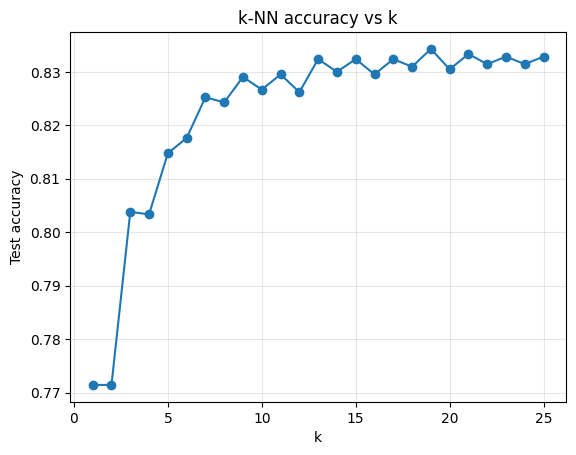

In [8]:
ks = list(range(1, 26))
acc = []
for k in ks:
    m = BruteKNN(k=k).fit(X_train, y_train)
    acc.append(np.mean(m.predict(X_test) == y_test))
best_k = ks[int(np.argmax(acc))]
print('Best k =', best_k, '| test accuracy =', round(max(acc), 4))

plt.plot(ks, acc, marker='o')
plt.xlabel('k'); plt.ylabel('Test accuracy'); plt.title('k-NN accuracy vs k')
plt.grid(alpha=0.3); plt.show()

In [9]:
print(f"{'k':>3s} {'ties':>6s} {'naive acc':>10s} {'tie-break acc':>14s}")
for k in [2, 4, 6, 8, 10]:
    naive = BruteKNN(k=k, tie_break=False).fit(X_train, y_train)
    fixed = BruteKNN(k=k, tie_break=True).fit(X_train, y_train)
    a1 = np.mean(naive.predict(X_test) == y_test)
    a2 = np.mean(fixed.predict(X_test) == y_test)
    print(f'{k:3d} {fixed.n_ties:6d} {a1:10.4f} {a2:14.4f}')

  k   ties  naive acc  tie-break acc
  2    449     0.7771         0.7714
  4    185     0.8090         0.8033
  6    130     0.8190         0.8176
  8    118     0.8257         0.8243
 10     79     0.8252         0.8267


## Analysis
(Apne run ke numbers dekhke yahan 2-3 line apne words me likho.)

- **Euclidean distance** ko matrix form me (`||a||^2 + ||b||^2 - 2a.b`) likhne se Python loop nahi chalta, isliye bahut tez hai.
- **Chunking** se ek baar me sirf `chunk x n_train` distance matrix banta hai, isliye bade dataset pe memory nahi phategi.
- **`argpartition`** sirf k nearest ko dhundta hai (O(n)), poori sorting (O(n log n)) nahi karni padti.
- **KD-tree** space ko dimension-wise baantta hai aur door wali branches skip kar deta hai (pruning). Ye low dimensions (2-10) me achha chalta hai, high dimensions me pruning kaam nahi karta aur brute force behtar ho jaata hai.
- Is 2D data pe KD-tree brute force se kaafi tez raha, kyunki pruning se bahut kam points check hote hain. Dimensions badhne pe ye fayda ghatta jaata hai (curse of dimensionality).
- **Ties:** even k ya multi-class me votes barabar ho sakte hain. Naive tareeka hamesha sabse chhota label deta hai (ek taraf ka bias). Distance-based tie-break paas wale points ko prefer karta hai, ye zyada principled hai. Accuracy me farak chhota hai (test set ~2100 points hai, to 0.5% ka farak noise ke andar hai), isliye tie-break ka fayda mainly fairness aur consistency me hai, bade accuracy jump me nahi.
- **k chhota** = noisy boundary (overfit), **k bada** = smooth boundary (underfit).